# Zeroes of Airy Disk

> Part of *PHYS 0241: Biomedical Imaging* (Prof. Michael E. Durst, Middlebury College). The [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch04/ch04-05.html) shows the rendered version together with the pre-rendered animations (course password required).
>
> **Start here:** no setup is needed for this notebook. In Google Colab, choose **File > Save a copy in Drive** to keep your changes.
>
> *Provided for academic use in PHYS 0241; please do not repost or redistribute ([terms of use](https://github.com/durstme/textbook-biomedicalimaging-notebooks/blob/main/LICENSE.md)).*

## Import libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.special import j1, jn_zeros

## Define parameters

In [2]:
# --- Parameters ---
L1 = 2 * 10**6       # Distance to screen in microns
wavelength1 = 0.632  # Wavelength in microns
d1 = 250              # slit separation in microns


# --- Data Generation ---
# Generate x values from -10 to 10
numpointsx1 = 512
x1 = np.linspace(-1e1,1e1,num=numpointsx1)
intensity1 = (2 * j1(x1) / x1)**2
intensity1 = np.nan_to_num(intensity1, nan=1.0) # fix divide by zero at center
airy_roots1 = jn_zeros(1, 3)

## Plot

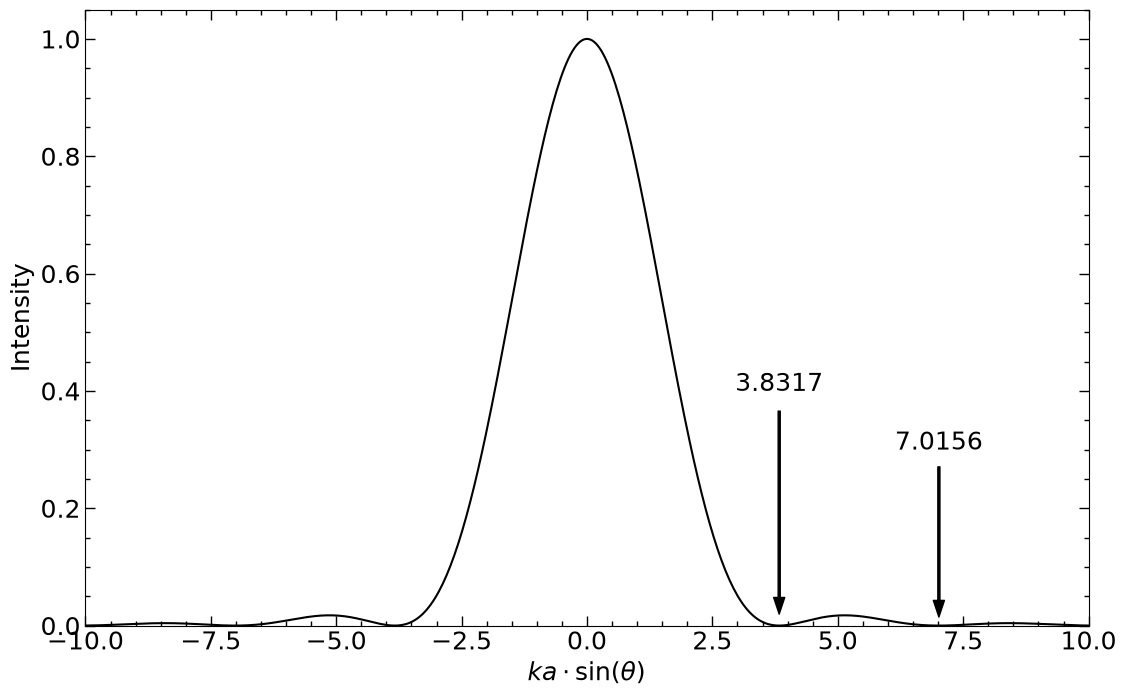

In [3]:
# --- Plotting ---
textsize1 = 18
#Sets the default font style and size in plots
font = {'family' : 'sans-serif',
        'size'   : textsize1}

plt.rc('font', **font)

fig1, ax1 = plt.subplots(figsize=(8*1.618,8))

ax1.plot(x1, intensity1, color='k', linewidth=1.5)
ax1.set_xlim(-10, 10)
ax1.set_ylim(0, 1.05)
ax1.set_xlabel(r"$ka \cdot \sin(\theta)$")
ax1.set_ylabel("Intensity")
ax1.minorticks_on()
ax1.tick_params(which='both',direction="in",width=1)
ax1.tick_params(which='major',length=7)
ax1.tick_params(which='minor',length=3.5)
ax1.xaxis.set_ticks_position('both')
ax1.yaxis.set_ticks_position('both')

# First Root Annotation
root1 = airy_roots1[0] # approx 3.8317
ax1.annotate(f"{root1:.4f}",                  # Text label
            xy=(root1, 0),                   # Point arrow aims at
            xytext=(root1, 0.4),             # Position of text/arrow tail
            horizontalalignment='center',
            fontsize=textsize1,
            arrowprops=dict(facecolor='black', shrink=0.05, width=1.5, headwidth=8))

# Second Root Annotation
root2 = airy_roots1[1] # approx 7.0156
ax1.annotate(f"{root2:.4f}", 
            xy=(root2, 0), 
            xytext=(root2, 0.3),             # Slightly lower start point
            horizontalalignment='center',
            fontsize=textsize1,
            arrowprops=dict(facecolor='black', shrink=0.05, width=1.5, headwidth=8))

plt.show()

# fig1.savefig("../figures/ch04/ch04-05-airydiskzeroes.jpg", dpi=300, bbox_inches='tight')